# Shoplifting Detection — Exploratory Data Analysis

**Reproducible EDA for the V6 CCTV video classification project.** This notebook measures properties of the original videos instead of relying on guessed metadata, and exports tidy CSVs, figures, and README-ready statistics.

**Outputs:** video inventory, duplicate analysis (SHA-256), video duration/FPS/resolution, class imbalance, 1-FPS sample counts, V6 split reconciliation, optional motion proxy, figures, and a README data-summary snippet.

> Dataset is not hosted in the GitHub repository. Run the notebook on Google Colab with Google Drive mounted or set `SHOPLIFTING_DATA_ROOT` to the raw dataset directory. No training is performed here. By default, no identifiable CCTV frames are exported.

In [1]:
from pathlib import Path
import os, re, json, hashlib, warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

DATA_ROOT = Path(os.environ.get(
    'SHOPLIFTING_DATA_ROOT',
    '/content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet'
)).expanduser()
OUTPUT_DIR = Path(os.environ.get(
    'SHOPLIFTING_EDA_OUTPUT',
    str(DATA_ROOT / 'shoplifting_eda_v2')
)).expanduser()
FIG_DIR = OUTPUT_DIR / 'assets' / 'eda'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# If V6 outputs exist, analyze exact train/test membership without creating a new split.
V6_SPLIT_CANDIDATES = [
    DATA_ROOT / 'shoplifting_independent_v6_no_attention' / 'video_split.csv',
    DATA_ROOT / 'test' / 'shoplifting_independent_v6_no_attention' / 'video_split.csv',
]
NORMAL_FOLDERS = {'non shop lifters','non shop lifter','normal','non shoplifting','non shoplifters'}
SHOP_FOLDERS = {'shop lifters','shop lifter','shoplifting','shoplifters','theft'}
EXTENSIONS = {'.mp4','.mov','.avi','.mkv'}
SEED = 42
plt.rcParams.update({'figure.figsize': (9, 4.5),'figure.dpi': 115,
                     'axes.spines.top': False,'axes.spines.right': False,
                     'font.size': 11})
assert DATA_ROOT.exists(), f'Dataset folder not found: {DATA_ROOT}'
print('Dataset:', DATA_ROOT)
print('Export directory:', OUTPUT_DIR)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR/name, dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()

Mounted at /content/drive
Dataset: /content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet
Export directory: /content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet/shoplifting_eda_v2


## 1. Raw inventory and labels

Infer labels strictly from the parent folder naming scheme used by V6, and avoid counting experiment caches outside those class folders. Scan media files without loading all frames into memory.

Original files: 855


,videos
class_name,
Normal,531
Shoplifting,324


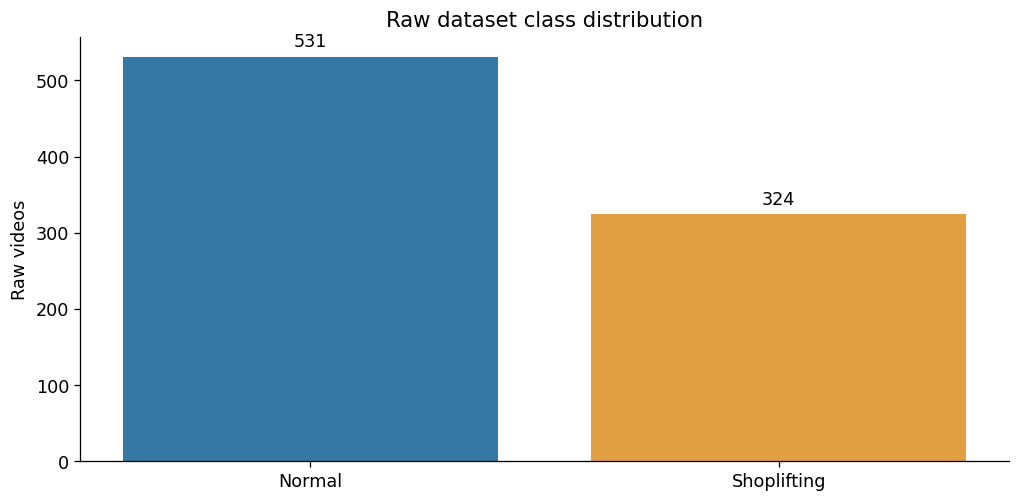

In [2]:
def infer_label(path):
    folders = [re.sub(r'[^a-z0-9]+',' ', s.lower()).strip()
               for s in path.relative_to(DATA_ROOT).parent.parts]
    if any(p in NORMAL_FOLDERS for p in folders):
        return 0
    if any(p in SHOP_FOLDERS for p in folders):
        return 1
    return None

rows=[]
for path in sorted(DATA_ROOT.rglob('*')):
    if not path.is_file() or path.suffix.lower() not in EXTENSIONS:
        continue
    if OUTPUT_DIR in path.parents:
        continue
    label=infer_label(path)
    if label is None:
        continue
    rows.append({'relative_path':path.relative_to(DATA_ROOT).as_posix(),
                 'label':label, 'class_name':'Shoplifting' if label else 'Normal',
                 'size_bytes':path.stat().st_size})
raw=pd.DataFrame(rows)
if raw.empty:
    raise RuntimeError('No videos found under labeled class folders. Check DATA_ROOT.')
assert raw.relative_path.is_unique
raw.to_csv(OUTPUT_DIR/'raw_video_inventory.csv', index=False)
print('Original files:',len(raw))
display(raw.groupby('class_name').size().rename('videos').to_frame())

counts=raw.class_name.value_counts().reindex(['Normal','Shoplifting'],fill_value=0)
fig,ax=plt.subplots()
bars=ax.bar(counts.index,counts.values,color=['#3478A6','#E19F42'])
ax.bar_label(bars,padding=4)
ax.set_ylabel('Raw videos'); ax.set_title('Raw dataset class distribution')
savefig('class_distribution.png')

## 2. Video metadata

Read the encoded frame count, FPS, duration, dimensions, aspect ratio and approximate 1-FPS frame count per file. Flag unreadable or nonsensical metadata instead of silently fabricating values.

Readable videos: 854 / 855


duration_seconds                             fps                \
                       count median   mean  min    max count median   mean   
class_name                                                                   
Normal                   530   14.0  13.93  3.0  74.00   530   25.0  24.97   
Shoplifting              324   12.0  12.22  4.0  23.03   324   25.0  24.92   

                         approx_1fps_frames                           
               min   max              count median   mean  min   max  
class_name                                                            
Normal       24.83  25.0                530   14.0  14.02  3.0  74.0  
Shoplifting  24.75  25.0                324   12.0  12.32  4.0  24.0

Top resolutions:


,count
resolution,
704x576,854
Unreadable,1


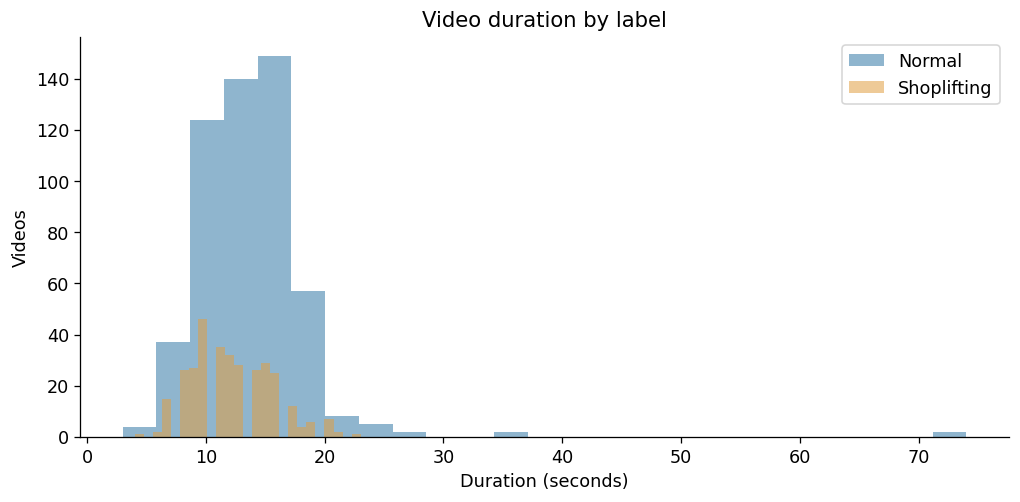

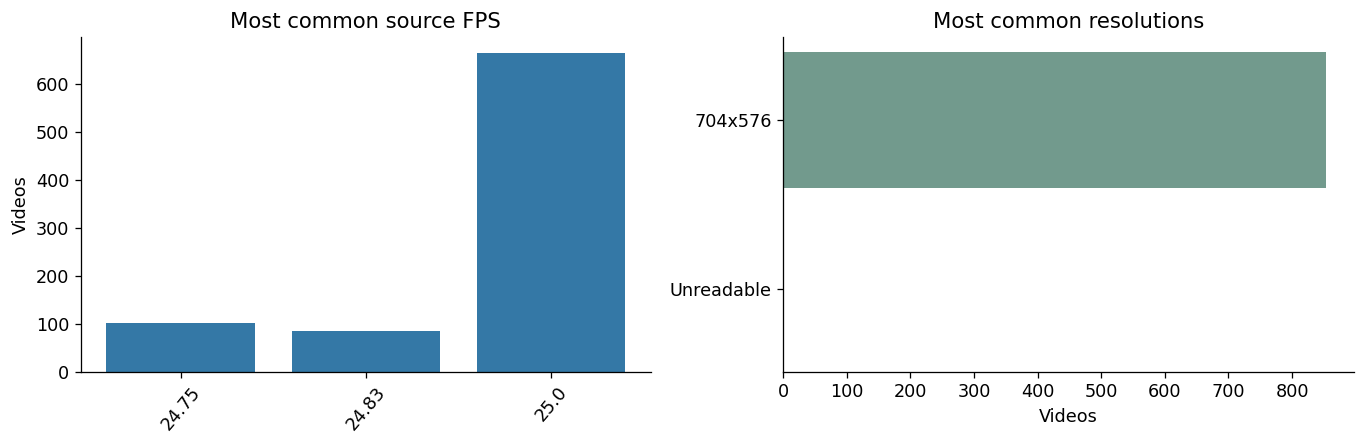

In [3]:
metadata=[]
for r in raw.itertuples(index=False):
    path=DATA_ROOT/r.relative_path
    cap=cv2.VideoCapture(str(path))
    opened=cap.isOpened()
    fps=cap.get(cv2.CAP_PROP_FPS) if opened else np.nan
    n=cap.get(cv2.CAP_PROP_FRAME_COUNT) if opened else np.nan
    w=cap.get(cv2.CAP_PROP_FRAME_WIDTH) if opened else np.nan
    h=cap.get(cv2.CAP_PROP_FRAME_HEIGHT) if opened else np.nan
    cap.release()
    valid=bool(opened and np.isfinite(fps) and 1<=fps<=240 and
               np.isfinite(n) and n>0 and np.isfinite(w) and np.isfinite(h) and
               w>0 and h>0)
    duration=float(n/fps) if valid else np.nan
    sampled=np.nan
    # 1-FPS sampling is at t = 0, 1, 2 ... until the last encoded frame.
    if valid:
        frame_ids=np.rint(np.arange(0,duration,1.0)*fps).astype(int)
        sampled=int(np.unique(frame_ids[(frame_ids>=0)&(frame_ids<int(n))]).size)
    metadata.append({'relative_path':r.relative_path,'metadata_ok':valid,
                     'fps':float(fps) if valid else np.nan,
                     'original_frames':int(n) if valid else np.nan,
                     'duration_seconds':duration,'width':int(w) if valid else np.nan,
                     'height':int(h) if valid else np.nan,
                     'approx_1fps_frames':sampled})
meta=pd.DataFrame(metadata)
full=raw.merge(meta,on='relative_path',validate='one_to_one')
full['resolution']=full.apply(lambda r:
    f'{int(r.width)}x{int(r.height)}' if r.metadata_ok else 'Unreadable',axis=1)
full['aspect_ratio']=full.width/full.height
full.to_csv(OUTPUT_DIR/'video_metadata.csv',index=False)
print('Readable videos:',int(full.metadata_ok.sum()),'/',len(full))
display(full.groupby('class_name')[['duration_seconds','fps','approx_1fps_frames']]
        .agg(['count','median','mean','min','max']).round(2))
print('Top resolutions:'); display(full.resolution.value_counts().head(10))

fig,ax=plt.subplots()
for label,color in [('Normal','#3478A6'),('Shoplifting','#E19F42')]:
    arr=full.loc[(full.class_name==label)&full.metadata_ok,'duration_seconds'].dropna()
    ax.hist(arr,bins=25,alpha=.55,label=label,color=color)
ax.set(xlabel='Duration (seconds)',ylabel='Videos',title='Video duration by label')
ax.legend();savefig('duration_distribution.png')

fig,axes=plt.subplots(1,2,figsize=(12,4))
round_fps=full.loc[full.metadata_ok,'fps'].round(2).value_counts().nlargest(10).sort_index()
axes[0].bar(round_fps.index.astype(str),round_fps.values,color='#3478A6')
axes[0].tick_params(axis='x',rotation=50);axes[0].set_title('Most common source FPS')
axes[0].set_ylabel('Videos')
rs=full.resolution.value_counts().head(8)
axes[1].barh(rs.index[::-1],rs.values[::-1],color='#729A8D')
axes[1].set_title('Most common resolutions');axes[1].set_xlabel('Videos')
plt.tight_layout();plt.savefig(FIG_DIR/'fps_resolution.png',dpi=180,bbox_inches='tight',facecolor='white');plt.show()

## 3. Exact duplicates (SHA-256)

File hashes identify byte-for-byte identical video files. They **do not** detect re-encodings, overlapping camera recordings, or visually similar sequences. All exact copies must be kept in one split, or deduplicated before splitting.

Original video files: 855
Exact duplicate extra files: 218
Unique files after exact dedup: 637
Duplicate groups (>1 file): 218


,hash_groups
file_count,
1,419
2,218


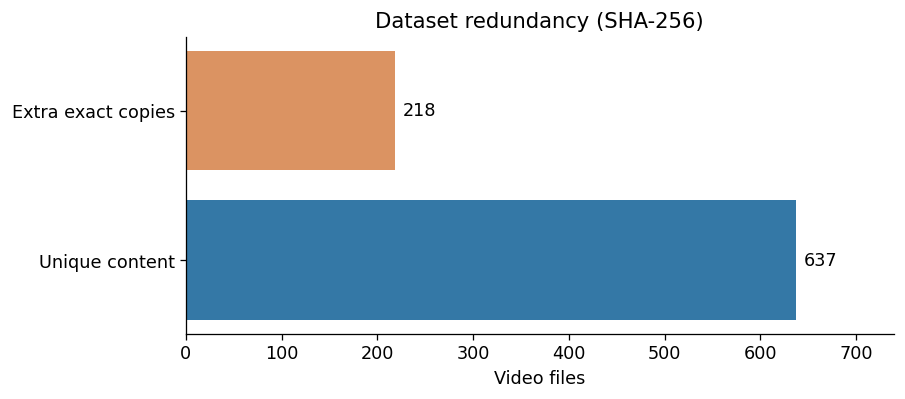

In [4]:
def sha256_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda: f.read(4*1024*1024), b''):
            h.update(block)
    return h.hexdigest()

raw['sha256']=[sha256_file(DATA_ROOT/p) for p in raw.relative_path]
assert raw.groupby('sha256').label.nunique().le(1).all(), 'Same video hash has conflicting labels'
unique=raw.drop_duplicates('sha256').copy().reset_index(drop=True)
raw.to_csv(OUTPUT_DIR/'raw_video_inventory_with_hashes.csv',index=False)
unique.to_csv(OUTPUT_DIR/'unique_video_inventory.csv',index=False)
duplicate_extra=len(raw)-len(unique)
groups=raw.groupby('sha256').agg(file_count=('sha256','size'),
                                 label=('class_name','first')).reset_index()
print('Original video files:',len(raw))
print('Exact duplicate extra files:',duplicate_extra)
print('Unique files after exact dedup:',len(unique))
print('Duplicate groups (>1 file):',int((groups.file_count>1).sum()))
display(groups.file_count.value_counts().sort_index().rename('hash_groups').to_frame().head(20))

fig,ax=plt.subplots(figsize=(8,3.6))
vals=[len(unique),duplicate_extra]
bars=ax.barh(['Unique content','Extra exact copies'],vals,color=['#3478A6','#DB9362'])
ax.bar_label(bars,padding=5)
ax.set(xlabel='Video files',title='Dataset redundancy (SHA-256)')
ax.set_xlim(0,max(vals)*1.16)
savefig('duplicate_summary.png')

## 4. Match the actual V6 train/test split

Do **not** generate a fresh split here. V6 already specifies the membership of all videos by SHA-256, and the notebook asserts the exact identities. Only report the split when the saved V6 manifest is accessible. Its existence does not rule out near-duplicate or temporally overlapping recordings across groups.

Verified split manifest: /content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet/shoplifting_independent_v6_no_attention/video_split.csv
Exactly matching data hashes: 632 / 632


,Normal,Shoplifting
split,,
train,263,274
test,47,48


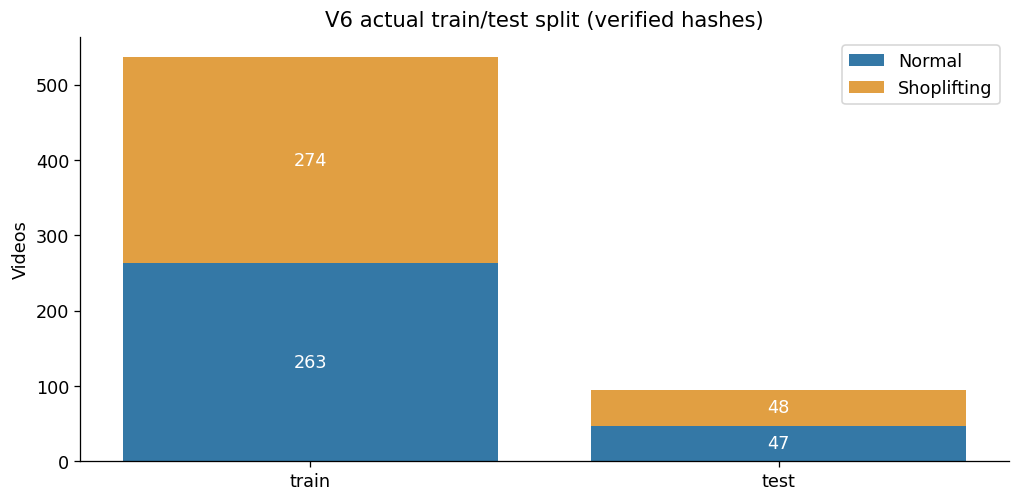

In [5]:
SPLIT_PATH=next((p for p in V6_SPLIT_CANDIDATES if p.is_file()),None)
split_summary=None
manifest=None
if SPLIT_PATH is None:
    print('V6 split manifest not found. Split figures skipped; EDA still runs independently.')
else:
    manifest=pd.read_csv(SPLIT_PATH)
    need={'sha256','label','split'}
    assert need.issubset(manifest.columns), f'Missing V6 split fields: {need-set(manifest.columns)}'
    assert manifest.sha256.is_unique, 'Duplicate content hashes in the V6 split'
    assert set(manifest.sha256.astype(str)).issubset(set(unique.sha256.astype(str)))
    merged=manifest[['sha256','label','split']].merge(
        unique[['sha256','label']],on='sha256',suffixes=('_v6','_raw'),validate='one_to_one')
    assert (merged.label_v6==merged.label_raw).all(), 'Raw and V6 class labels disagree'
    assert set(merged.split).issubset({'train','test'})
    split_summary=pd.crosstab(merged.split,merged.label_v6).reindex(
        index=['train','test'],columns=[0,1],fill_value=0)
    split_summary.columns=['Normal','Shoplifting']
    print('Verified split manifest:',SPLIT_PATH)
    print('Exactly matching data hashes:',len(merged),'/',len(manifest))
    display(split_summary)
    split_summary.to_csv(OUTPUT_DIR/'v6_split_class_counts.csv')
    fig,ax=plt.subplots()
    bottom=np.zeros(len(split_summary))
    for label,color in [('Normal','#3478A6'),('Shoplifting','#E19F42')]:
        vals=split_summary[label].to_numpy()
        bars=ax.bar(split_summary.index,vals,bottom=bottom,label=label,color=color)
        ax.bar_label(bars,labels=[str(v) for v in vals],label_type='center',color='white')
        bottom+=vals
    ax.set(ylabel='Videos',title='V6 actual train/test split (verified hashes)')
    ax.legend();savefig('split_distribution.png')

## 5. Data quality and temporal coverage

Show the distribution of the number of frames retained at 1 FPS, duration outliers, unreadable files, and possible group leakage. Large temporal gaps are a limitation of 1-FPS subsampling, not proof that the model captures brief hand/object actions.

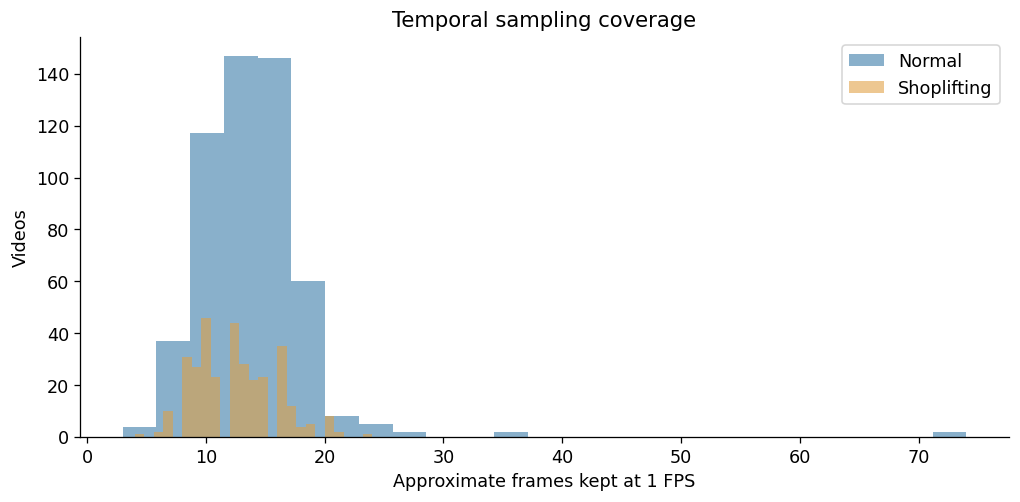

Metadata issues: 1
Median duration (s): 13.0
Median 1-FPS frames: 13
Very short videos (<5s): 3
Long videos (>60s): 2

Longest clips:


,relative_path,class_name,duration_seconds,fps,resolution
69,non shop lifters/shop_lifter_n_13.mp4,Normal,74.0,25.0,704x576
90,non shop lifters/shop_lifter_n_13_1.mp4,Normal,74.0,25.0,704x576
313,non shop lifters/shop_lifter_n_44.mp4,Normal,36.0,25.0,704x576
314,non shop lifters/shop_lifter_n_44_1.mp4,Normal,36.0,25.0,704x576
236,non shop lifters/shop_lifter_n_206.mp4,Normal,26.0,25.0,704x576
237,non shop lifters/shop_lifter_n_206_1.mp4,Normal,26.0,25.0,704x576
361,non shop lifters/shop_lifter_n_66.mp4,Normal,25.0,25.0,704x576
362,non shop lifters/shop_lifter_n_66_1.mp4,Normal,25.0,25.0,704x576


Exact-hash train/test collisions: 0 (verified)
Near duplicates / recording overlaps: NOT established by exact hashes


In [6]:
valid=full[full.metadata_ok].copy()
fig,ax=plt.subplots()
for label,color in [('Normal','#3478A6'),('Shoplifting','#E19F42')]:
    xx=valid.loc[valid.class_name==label,'approx_1fps_frames'].dropna()
    ax.hist(xx,bins=25,alpha=.58,label=label,color=color)
ax.set(xlabel='Approximate frames kept at 1 FPS',ylabel='Videos',
       title='Temporal sampling coverage')
ax.legend();savefig('sampled_frames_distribution.png')

print('Metadata issues:',len(full)-len(valid))
print('Median duration (s):',round(float(valid.duration_seconds.median()),2) if len(valid) else 'n/a')
print('Median 1-FPS frames:',int(valid.approx_1fps_frames.median()) if len(valid) else 'n/a')
print('Very short videos (<5s):',int((valid.duration_seconds<5).sum()))
print('Long videos (>60s):',int((valid.duration_seconds>60).sum()))
print('\nLongest clips:')
display(valid.nlargest(8,'duration_seconds')[['relative_path','class_name','duration_seconds','fps','resolution']])

if manifest is not None:
    assert not manifest.loc[manifest.split=='train','sha256'].isin(
        manifest.loc[manifest.split=='test','sha256']).any()
    print('Exact-hash train/test collisions: 0 (verified)')
    print('Near duplicates / recording overlaps: NOT established by exact hashes')

## 6. Optional motion proxy: sampled consecutive-frame differences

This is an **exploratory motion score**, not an annotation of theft and not an object tracker. For a small, reproducible stratified sample from the exact-hash-unique inventory, decode up to a few 1-second-spaced frames, grayscale them, and summarize absolute differences. Static backgrounds dominate surveillance footage; interpret carefully. This section can be skipped if video reading is expensive.

In [7]:
RUN_MOTION_EDA = False  # Set True to opt in; not needed for the README headline statistics.
MOTION_SAMPLES_PER_CLASS = 24

def motion_proxy(relative_path,max_frames=7):
    cap=cv2.VideoCapture(str(DATA_ROOT/relative_path))
    if not cap.isOpened(): return np.nan
    fps=cap.get(cv2.CAP_PROP_FPS)
    n=cap.get(cv2.CAP_PROP_FRAME_COUNT)
    if not np.isfinite(fps) or fps<=0 or not np.isfinite(n) or n<=0:
        cap.release();return np.nan
    times=np.arange(0,min(n/fps,max_frames),1.)
    frames=[]
    for t in times:
        cap.set(cv2.CAP_PROP_POS_FRAMES,int(round(t*fps)))
        success,bgr=cap.read()
        if not success: continue
        img=cv2.resize(cv2.cvtColor(bgr,cv2.COLOR_BGR2GRAY),(96,96),interpolation=cv2.INTER_AREA)
        frames.append(img.astype(np.float32))
    cap.release()
    if len(frames)<2:return np.nan
    return float(np.mean([np.abs(b-a).mean() for a,b in zip(frames[:-1],frames[1:])]))

if RUN_MOTION_EDA:
    samples=(unique.groupby('class_name',group_keys=False)
             .apply(lambda x:x.sample(n=min(len(x),MOTION_SAMPLES_PER_CLASS),random_state=SEED))
             .reset_index(drop=True))
    samples['motion_proxy']=samples.relative_path.map(motion_proxy)
    samples.to_csv(OUTPUT_DIR/'motion_sample_summary.csv',index=False)
    fig,ax=plt.subplots()
    data=[samples.loc[samples.class_name==c,'motion_proxy'].dropna() for c in ['Normal','Shoplifting']]
    ax.boxplot(data,tick_labels=['Normal','Shoplifting'],showfliers=False)
    ax.set(ylabel='Mean absolute pixel change (gray, 0–255)',
           title='Exploratory motion proxy (sampled videos)')
    savefig('motion_proxy.png')
    print('Motion proxy is not an objective theft feature or classification accuracy.')
else:
    print('Motion EDA skipped (RUN_MOTION_EDA=False).')

Motion EDA skipped (RUN_MOTION_EDA=False).


## 7. Export README-ready facts

Writes `eda_summary.json` and a Markdown snippet using values **actually measured in this run**. Move `assets/eda/` plots into the GitHub repository to display them in `README.md`. The README packaged with the repository already embeds the four results that were verifiable from the executed V6 notebook. Re-run here to recompute if your local dataset changes.

In [8]:
summary={
 'raw_total':int(len(raw)),
 'raw_normal':int((raw.label==0).sum()),
 'raw_shoplifting':int((raw.label==1).sum()),
 'sha256_extra_exact_copies':int(duplicate_extra),
 'sha256_unique_videos':int(len(unique)),
 'metadata_readable_videos':int(full.metadata_ok.sum()),
 'median_duration_seconds':float(valid.duration_seconds.median()) if len(valid) else None,
 'median_fps':float(valid.fps.median()) if len(valid) else None,
 'median_1fps_frames':float(valid.approx_1fps_frames.median()) if len(valid) else None,
 'most_common_resolution':full.loc[full.metadata_ok,'resolution'].mode().iloc[0] if len(valid) else None,
 'v6_manifest_available':manifest is not None,
 'v6_split_counts':split_summary.astype(int).to_dict(orient='index') if split_summary is not None else None,
 'limitations':['SHA-256 finds exact bytes only','Recording-session overlap not ruled out',
                'Most videos originate from fixed-view CCTV; camera generalization is untested']
}
(OUTPUT_DIR/'eda_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')

lines=['## Dataset EDA (auto-generated)','',
       f"- Raw videos: **{summary['raw_total']:,}** (Normal: **{summary['raw_normal']:,}**, Shoplifting: **{summary['raw_shoplifting']:,}**).",
       f"- Exact redundant copies: **{summary['sha256_extra_exact_copies']:,}**; unique SHA-256 hashes: **{summary['sha256_unique_videos']:,}**.",
       f"- Valid video metadata: **{summary['metadata_readable_videos']:,}** files.",
       f"- Median video duration: **{summary['median_duration_seconds']:.2f}s**." if summary['median_duration_seconds'] is not None else '- Median duration unavailable.',
       f"- Median original FPS: **{summary['median_fps']:.2f}**." if summary['median_fps'] is not None else '- Median FPS unavailable.',
       f"- Most common original resolution: **{summary['most_common_resolution']}**.",
       '', 'Figures (copy `assets/eda/*.png` into the repo):','',
       '![Raw class distribution](assets/eda/class_distribution.png)',
       '![Duplicate summary](assets/eda/duplicate_summary.png)',
       '![Video duration](assets/eda/duration_distribution.png)',
       '![FPS and resolution](assets/eda/fps_resolution.png)']
if split_summary is not None:
    lines.insert(7,f"- V6 split: **{int(split_summary.loc['train'].sum())} train** / **{int(split_summary.loc['test'].sum())} test** (no validation).")
(OUTPUT_DIR/'EDA_README_SNIPPET.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
print('Wrote:',OUTPUT_DIR/'eda_summary.json')
print('Wrote:',OUTPUT_DIR/'EDA_README_SNIPPET.md')
print('Figures:',*[p.name for p in sorted(FIG_DIR.glob('*.png'))],sep='\n  • ')
display(pd.DataFrame([summary]).T.rename(columns={0:'value'}))

Wrote: /content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet/shoplifting_eda_v2/eda_summary.json
Wrote: /content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet/shoplifting_eda_v2/EDA_README_SNIPPET.md
Figures:
  • class_distribution.png
  • duplicate_summary.png
  • duration_distribution.png
  • fps_resolution.png
  • sampled_frames_distribution.png
  • split_distribution.png


,value
raw_total,855
raw_normal,531
raw_shoplifting,324
sha256_extra_exact_copies,218
sha256_unique_videos,637
metadata_readable_videos,854
median_duration_seconds,13.0
median_fps,25.0
median_1fps_frames,13.0
most_common_resolution,704x576
